# Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Model Parameters (from slide specifications)

In [5]:
params = {
    'c_s': 420.0,     # Soil water holding capacity (mm)
    'alpha': 4.0,     # Runoff function shape parameter
    'gamma': 0.5,     # ET function shape parameter
    'beta_0': 0.8     # Maximum of ET function
}

# Initial State Variable: 0.9 * c_s as initial value
initial_sm = 0.9 * swbm_params['c_s']

df = pd.read_csv("E:/VS_CODE_FILES/REMOTE_FILES/GitHub_Repos/Earth-System-Modelling/data/Data_swbm_Germany.csv")

# Note: R_n is assumed to be in water equivalent (mm/day), i.e., R_n / (lambda * rho_w)
days = 365
np.random.seed(42)
driving_data = pd.DataFrame({
    'day': np.arange(days),
    'P': np.random.gamma(shape=1.5, scale=2.0, size=days),  # Precipitation (mm/day)
    'R_n': 3.5 + 2.5 * np.sin(np.arange(days) / days * 2 * np.pi)  # Net radiation (mm/day eq.)
})

driving_data['R_n'] = driving_data['R_n'].clip(lower=0)

# Model Components output

In [9]:
print("Model Components:")
print("\nParameters:")
for param, value in params.items():
  print(f"  {param}: {value}")
print(f"\nInitial Soil Moisture: {initial_sm:.1f} mm")
print("\nDriving Data Summary:")
print(f"  Total Rainfall (P): {driving_data['P'].sum():.1f} mm")
print(
    f"  Average Radiation (R): {driving_data['R_n'].mean():.2f} mm/day"
)

Model Components:

Parameters:
  c_s: 420.0
  alpha: 4.0
  gamma: 0.5
  beta_0: 0.8

Initial Soil Moisture: 378.0 mm

Driving Data Summary:
  Total Rainfall (P): 1111.9 mm
  Average Radiation (R): 3.50 mm/day


# Core Flux & State Functions


In [10]:
def calculate_runoff(sm, precip, c_s, alpha):
    """
    Calculate daily runoff Q_n (mm/day).
    Equation: Q_n = P_n * (w_n / c_s)^alpha
    """

    rel_sm = np.clip(sm / c_s, 0.0, 1.0)   # Relative soil moisture (capped between 0 and 1 for numerical stability)
    runoff_fraction = rel_sm ** alpha
    return precip * runoff_fraction

def calculate_et(sm, rad, c_s, beta_0, gamma):
    """
    Calculate daily evapotranspiration ET_n (mm/day).
    Equation: ET_n = R_n * beta_0 * (w_n / c_s)^gamma
    (Assuming rad is already in mm/day water equivalent: R_n / (lambda * rho_w))
    """
    rel_sm = np.clip(sm / c_s, 0.0, 1.0)
    et_fraction = beta_0 * (rel_sm ** gamma)
    return rad * et_fraction

def calculate_infiltration(precip, runoff):
    """
    Calculate water entering the soil (mm/day).
    Infiltration = Precipitation - Runoff
    """
    return precip - runoff

# Simulation Loop

In [12]:
def run_swbm(driving_df, params, initial_soil_moisture):
    n_steps = len(driving_df)
    
    sm = np.zeros(n_steps + 1)
    sm[0] = initial_soil_moisture
    
    runoff_ts = np.zeros(n_steps)
    et_ts = np.zeros(n_steps)
    infil_ts = np.zeros(n_steps)
    
    for t in range(n_steps):
        w_n = sm[t]
        p_n = driving_df['P'].iloc[t]
        r_n = driving_df['R_n'].iloc[t]
        
        # Calculate fluxes
        q_n = calculate_runoff(w_n, p_n, params['c_s'], params['alpha'])
        et_n = calculate_et(w_n, r_n, params['c_s'], params['beta_0'], params['gamma'])
        inf_n = calculate_infiltration(p_n, q_n)
        
        # Water balance update: w_{n+1} = w_n + (P_n - E_n - Q_n) * dt (with dt = 1 day)
        w_next = w_n + p_n - et_n - q_n
        
        # soil moisture cannot drop below 0 or exceed c_s
        sm[t + 1] = np.clip(w_next, 0.0, params['c_s'])
        
        runoff_ts[t] = q_n
        et_ts[t] = et_n
        infil_ts[t] = inf_n
        
    results = driving_df.copy()
    results['SM'] = sm[:-1]  # Soil moisture at start of day t
    results['Runoff'] = runoff_ts
    results['ET'] = et_ts
    results['Infiltration'] = infil_ts
    
    return results

sim_results = run_swbm(driving_data, swbm_params, initial_sm)
print(sim_results.head())

   day         P       R_n          SM    Runoff        ET  Infiltration
0    0  3.579246  3.500000  378.000000  2.348344  2.656313      1.230903
1    1  2.047212  3.543033  376.574590  1.323030  2.683899      0.724182
2    2  1.863176  3.586054  374.614873  1.179225  2.709410      0.683951
3    3  1.863206  3.629049  372.589414  1.153947  2.734472      0.709259
4    4  7.677526  3.672006  370.564201  4.652410  2.759310      3.025116


# Visualization

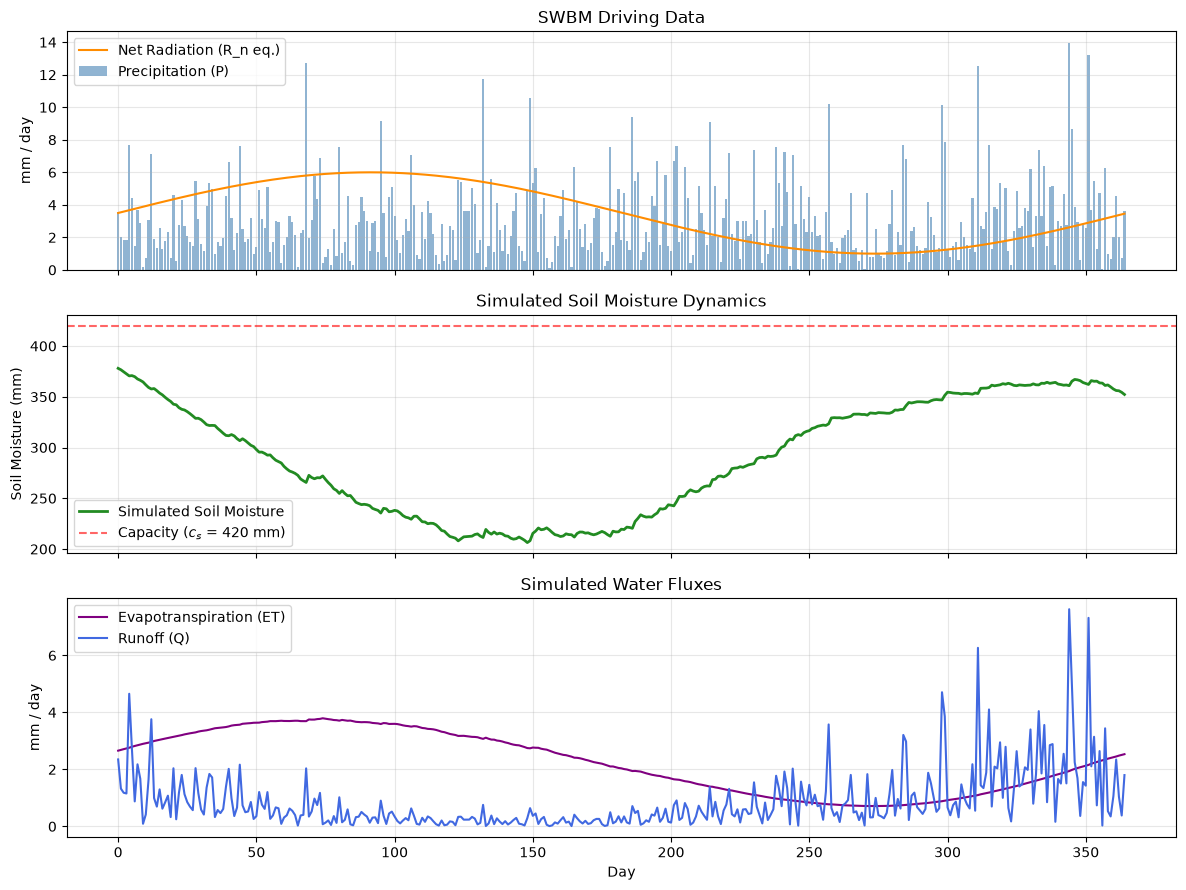

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Panel 1: Driving Data
axes[0].bar(sim_results['day'], sim_results['P'], color='steelblue', alpha=0.6, label='Precipitation (P)')
axes[0].plot(sim_results['day'], sim_results['R_n'], color='darkorange', linewidth=1.5, label='Net Radiation (R_n eq.)')
axes[0].set_ylabel('mm / day')
axes[0].set_title('SWBM Driving Data')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel 2: Soil Moisture (State Variable)
axes[1].plot(sim_results['day'], sim_results['SM'], color='forestgreen', linewidth=2, label='Simulated Soil Moisture')
axes[1].axhline(swbm_params['c_s'], color='red', linestyle='--', alpha=0.6, label='Capacity ($c_s$ = 420 mm)')
axes[1].set_ylabel('Soil Moisture (mm)')
axes[1].set_title('Simulated Soil Moisture Dynamics')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Panel 3: Outgoing Fluxes (ET and Runoff)
axes[2].plot(sim_results['day'], sim_results['ET'], color='purple', linewidth=1.5, label='Evapotranspiration (ET)')
axes[2].plot(sim_results['day'], sim_results['Runoff'], color='royalblue', linewidth=1.5, label='Runoff (Q)')
axes[2].set_xlabel('Day')
axes[2].set_ylabel('mm / day')
axes[2].set_title('Simulated Water Fluxes')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()